In [1]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [2]:
data = {
    'Age' : ['youth','youth','middle','senior','senior','middle','senior','youth','youth', 'senior','youth','middle','middle','senior'],
    'Income' : ['high','high','high','medium','low','low','low','medium','low','medium','medium','medium','high','medium'],
    'Student' : ['no','no','no','no','yes','yes','yes','no','yes','yes','yes','no','yes','no'],
    'credit_rating' : ['fair','excellent','fair','fair','fair','excellent','excellent','fair','fair','fair','excellent','excellent','fair','excellent'],
    'buys_computer' : ['no','no','yes','yes','yes','no','yes','no','yes','yes','yes','yes','yes','no']
}


In [3]:
df = pd.DataFrame(data)

In [4]:
df

,Age,Income,Student,credit_rating,buys_computer
0,youth,high,no,fair,no
1,youth,high,no,excellent,no
2,middle,high,no,fair,yes
3,senior,medium,no,fair,yes
4,senior,low,yes,fair,yes
5,middle,low,yes,excellent,no
6,senior,low,yes,excellent,yes
7,youth,medium,no,fair,no
8,youth,low,yes,fair,yes
9,senior,medium,yes,fair,yes


In [6]:
# encode categorical-> numeric
le = {} #create empty dict
df_enc = df.copy() #here we just copy our original data
for col in df.columns: #it convert into the text using loop through the column
    le[col] = LabelEncoder() #now create label for cureent data
    df_enc[col] = le[col].fit_transform(df[col]) #it learn unique value and transform text to value

In [7]:
df_enc

,Age,Income,Student,credit_rating,buys_computer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1
5,0,1,1,0,0
6,1,1,1,0,1
7,2,2,0,1,0
8,2,1,1,1,1
9,1,2,1,1,1


In [8]:
#features nd target
X = df_enc[['Age','Income','Student','credit_rating']]
y = df_enc['buys_computer']

In [9]:
X

,Age,Income,Student,credit_rating
0,2,0,0,1
1,2,0,0,0
2,0,0,0,1
3,1,2,0,1
4,1,1,1,1
5,0,1,1,0
6,1,1,1,0
7,2,2,0,1
8,2,1,1,1
9,1,2,1,1


In [11]:
y

,buys_computer
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


In [12]:
model = CategoricalNB() #apply model
model.fit(X,y) #fir ur values

CategoricalNB()

In [16]:
test = [['youth','medium','yes','fair']]

In [14]:
test

[['youth', 'meduim', 'yes', 'fair']]

In [23]:
print("\n--- Prediction -----------------------------")
for t in test:
  row = [[
      le['Age'].transform([t[0]])[0],
      le['Income'].transform([t[1]])[0],
      le['Student'].transform([t[2]])[0],
      le['credit_rating'].transform([t[3]])[0]
  ]]
  pred = le['buys_computer'].inverse_transform(model.predict(row))[0]
  prob = model.predict_proba(row)[0]
  print(f"Input : Age={t[0]}, Income={t[1]}, Student={t[2]}, CreditRating={t[3]}")
  print(f"Result: Buys Computer -> {pred}")
  print(f"P(No) = {prob[0]:.4f}")
  print(f"P(Yes) = {prob[1]:.4f}")


--- Prediction -----------------------------
Input : Age=youth, Income=medium, Student=yes, CreditRating=fair
Result: Buys Computer -> yes
P(No) = 0.2322
P(Yes) = 0.7678


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [24]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X)
print(f"\nTraining Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


Training Accuracy: 78.57%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


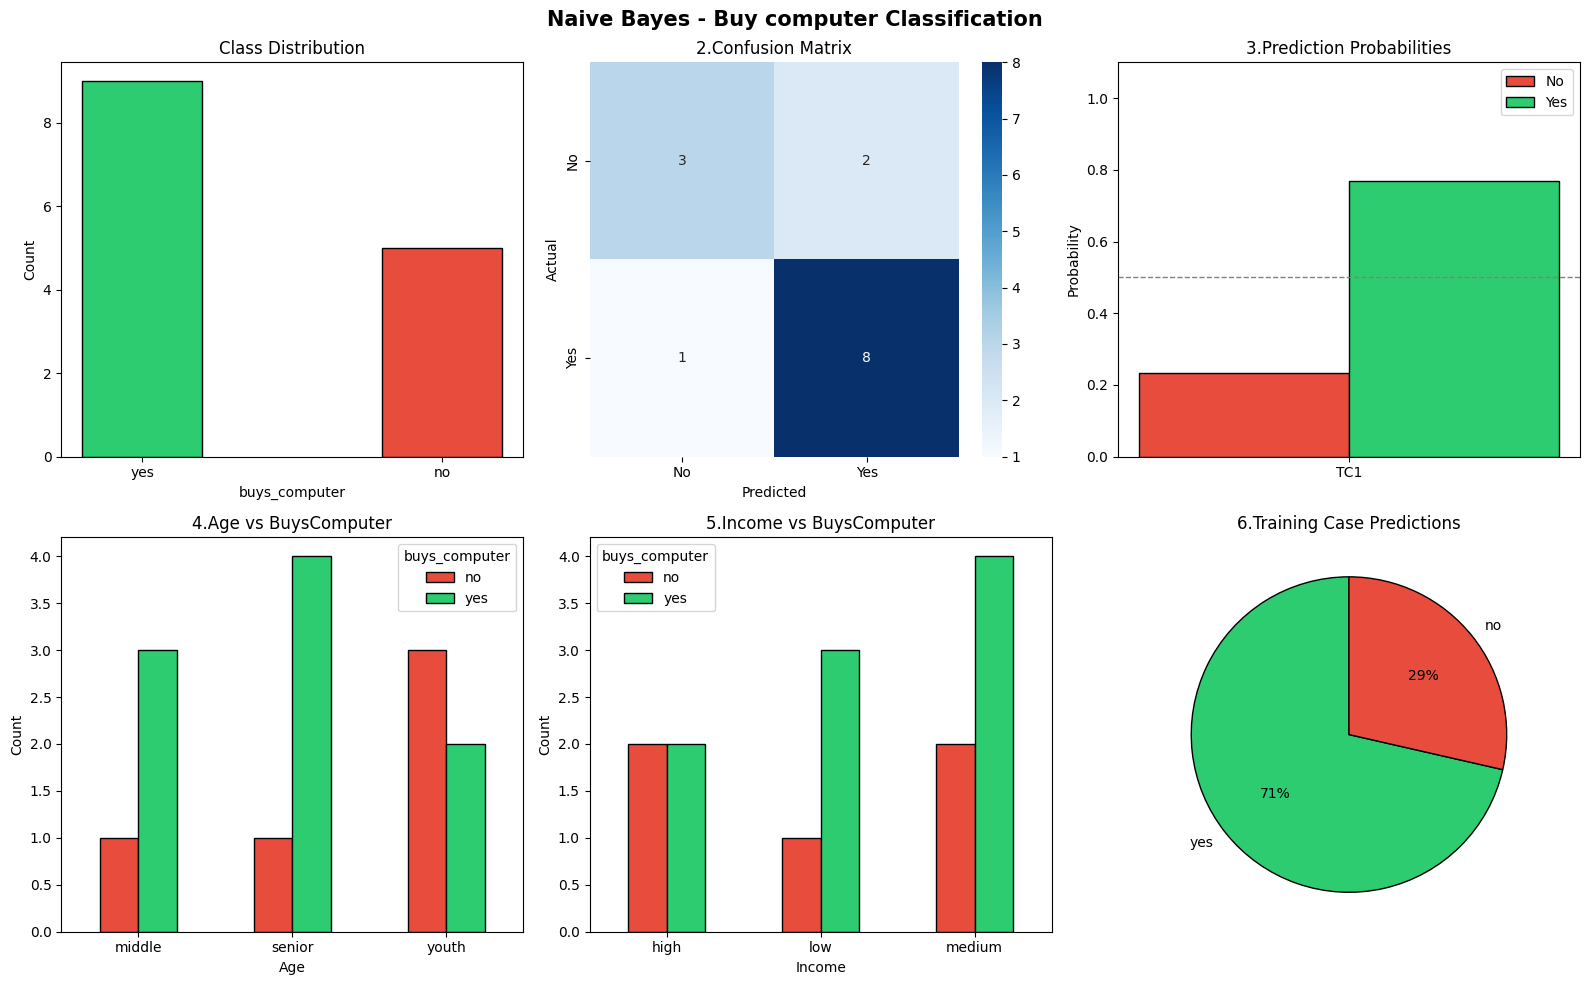

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Calculate the missing probabilities for Plot 3
# Let's dynamically compute the probabilities for each test case in `test`
test_encoded = []
for t in test:
    test_encoded.append([
        le['Age'].transform([t[0]])[0],
        le['Income'].transform([t[1]])[0],
        le['Student'].transform([t[2]])[0],
        le['credit_rating'].transform([t[3]])[0]
    ])
test_probs = model.predict_proba(test_encoded)
probs_no = test_probs[:, 0]
probs_yes = test_probs[:, 1]

# plots-----------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Naive Bayes - Buy computer Classification", fontsize=15, fontweight='bold')

# 1.Class Distribution (fix casing: 'buys_computer')
counts = df['buys_computer'].value_counts()
axes[0,0].bar(counts.index, counts.values, color=['#2ecc71', '#e74c3c'], edgecolor='black', width=0.4)
axes[0,0].set_title("Class Distribution")
axes[0,0].set_xlabel("buys_computer")
axes[0,0].set_ylabel("Count")

# 2.Confusion Matrix (fix casing: 'credit_rating')
x_features = df_enc[['Age', 'Income', 'Student', 'credit_rating']]
cm = confusion_matrix(y, model.predict(x_features))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=axes[0,1])
axes[0,1].set_title("2.Confusion Matrix")
axes[0,1].set_xlabel("Predicted")
axes[0,1].set_ylabel("Actual")

# 3.Prediction Probabilities (Grouped Bar)
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_indices = np.arange(len(tc_labels))
width = 0.3
axes[0,2].bar(x_indices - width/2, probs_no, width, label='No', color='#e74c3c', edgecolor='black')
axes[0,2].bar(x_indices + width/2, probs_yes, width, label='Yes', color='#2ecc71', edgecolor='black')
axes[0,2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0,2].set_title("3.Prediction Probabilities")
axes[0,2].set_xticks(x_indices)
axes[0,2].set_xticklabels(tc_labels)
axes[0,2].set_ylabel("Probability")
axes[0,2].set_ylim(0, 1.1)
axes[0,2].legend()

# 4.Age vs BuysComputer (fix casing: 'buys_computer')
age_counts = df.groupby(['Age', 'buys_computer']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[1,0], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1,0].set_title("4.Age vs BuysComputer")
axes[1,0].set_xlabel("Age")
axes[1,0].set_ylabel("Count")
axes[1,0].legend(title='buys_computer')

# 5.Income vs BuysComputer (fix casing: 'buys_computer')
income_counts = df.groupby(['Income', 'buys_computer']).size().unstack(fill_value=0)
income_counts.plot(kind='bar', ax=axes[1,1], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1,1].set_title("5.Income vs BuysComputer")
axes[1,1].set_xlabel("Income")
axes[1,1].set_ylabel("Count")
axes[1,1].legend(title='buys_computer')

# 6.pie Chart - Final Predictions (fix casing: 'buys_computer')
pred_counts = pd.Series(y_pred).value_counts()
# Mapping encoded indices back to labels for pie chart legend
pred_counts.index = le['buys_computer'].inverse_transform(pred_counts.index)
colors_pie = ['#2ecc71' if label == 'yes' else '#e74c3c' for label in pred_counts.index]
axes[1,2].pie(pred_counts, labels=pred_counts.index, autopct='%1.0f%%', colors=colors_pie, startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1,2].set_title("6.Training Case Predictions")
plt.tight_layout()
plt.show()